In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [3]:
MAX_INTENSITY = 255.0
x_train_full = x_train_full.astype("float32") / MAX_INTENSITY
x_test = x_test.astype("float32") / MAX_INTENSITY

N_TRAIN = 50_000
x_val, y_val = x_train_full[N_TRAIN:], y_train_full[N_TRAIN]
x_train, y_train = x_train_full[:N_TRAIN], y_train_full[:N_TRAIN]

In [4]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]


In [5]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (50000, 28, 28), val: (10000, 28, 28), test: (10000, 28, 28), class: 10


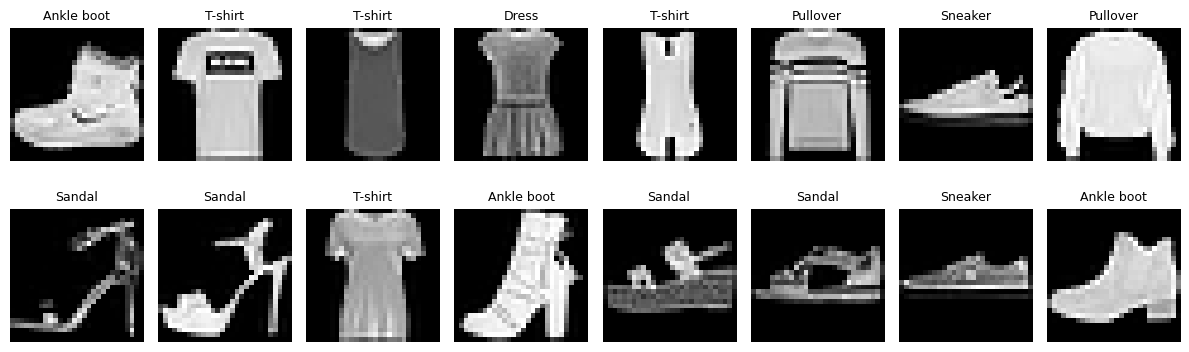

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Early stopping

In [7]:
model = keras.Sequential([
    keras.layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


model_1 = keras.Sequential([
    keras.layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_1.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [9]:
result = model.fit(x_train, y_train, validation_split=0.2, epochs=80, batch_size=32)

Epoch 1/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 763us/step - accuracy: 0.8591 - loss: 0.3910 - val_accuracy: 0.8580 - val_loss: 0.3926
Epoch 2/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 760us/step - accuracy: 0.8699 - loss: 0.3534 - val_accuracy: 0.8681 - val_loss: 0.3692
Epoch 3/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 733us/step - accuracy: 0.8795 - loss: 0.3270 - val_accuracy: 0.8755 - val_loss: 0.3403
Epoch 4/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 731us/step - accuracy: 0.8845 - loss: 0.3090 - val_accuracy: 0.8781 - val_loss: 0.3388
Epoch 5/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 731us/step - accuracy: 0.8929 - loss: 0.2918 - val_accuracy: 0.8760 - val_loss: 0.3430
Epoch 6/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 732us/step - accuracy: 0.8968 - loss: 0.2775 - val_accuracy: 0.8843 - val_loss: 0.3248
Epoch 7/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 712us/step - accuracy: 0.9011 - loss: 0.2656 - val_accuracy: 0.8882 - val_loss: 0.3179
Epoch 8/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 736us/step - accuracy: 0.9034 -

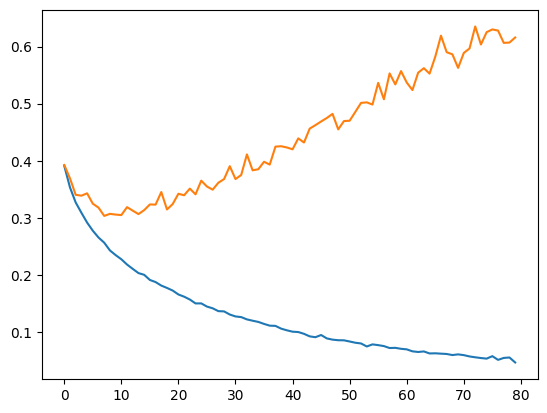

In [10]:
plt.plot(result.history["loss"], label="train loss")
plt.plot(result.history["val_loss"], label="validation loss")
plt.show()

In [12]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
result_1 = model_1.fit(x_train, y_train, validation_split=0.2, epochs=80, batch_size=32, callbacks=[early_stop])

Epoch 1/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 785us/step - accuracy: 0.8597 - loss: 0.3915 - val_accuracy: 0.8701 - val_loss: 0.3624
Epoch 2/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 714us/step - accuracy: 0.8729 - loss: 0.3507 - val_accuracy: 0.8691 - val_loss: 0.3578
Epoch 3/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 718us/step - accuracy: 0.8798 - loss: 0.3281 - val_accuracy: 0.8717 - val_loss: 0.3514
Epoch 4/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 724us/step - accuracy: 0.8881 - loss: 0.3067 - val_accuracy: 0.8768 - val_loss: 0.3440
Epoch 5/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 756us/step - accuracy: 0.8944 - loss: 0.2888 - val_accuracy: 0.8814 - val_loss: 0.3291
Epoch 6/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 732us/step - accuracy: 0.8967 - loss: 0.2763 - val_accuracy: 0.8808 - val_loss: 0.3284
Epoch 7/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 736us/step - accuracy: 0.9029 - loss: 0.2641 - val_accuracy: 0.8922 - val_loss: 0.3023
Epoch 8/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 732us/step - accuracy: 0.9061 -

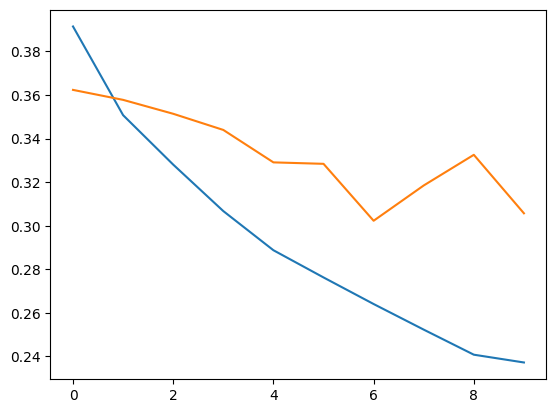

In [13]:
plt.plot(result_1.history["loss"], label="train loss model_1")
plt.plot(result_1.history["val_loss"], label="validation loss model_1")
plt.show()